# Course project: Intelligent Systems

## Author

### Tihomir Minev

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import os

# 1. Data description

The dataset contains information about credit card transactions.
(https://www.kaggle.com/datasets/dhanushnarayananr/credit-card-fraud?resource=download)

In [2]:
data=pd.read_csv('card_transdata.csv')

In [3]:
data.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0.0
1,10.829943,0.175592,1.294219,1.0,0.0,0.0,0.0,0.0
2,5.091079,0.805153,0.427715,1.0,0.0,0.0,1.0,0.0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0.0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0.0


**The dataset contains 1,000,000 credit card transactions and their behaviour.**

The goal is to classify whether a transaction is fraudulent.

## Data:

- distance_from_home – distance from the customer's home
- distance_from_last_transaction – distance from the last transaction
- ratio_to_median_purchase_price – ratio to the median purchase price
- repeat_retailer – whether the retailer has been used before
- used_chip – whether the chip was used
- used_pin_number – whether a PIN code was used
- online_order – whether the order was placed online
- fraud – whether the transaction is fraudulent (target variable), 1 -> fraud, 0 -> not fraud

**Structure of the dataset**

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 8 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   distance_from_home              1000000 non-null  float64
 1   distance_from_last_transaction  1000000 non-null  float64
 2   ratio_to_median_purchase_price  1000000 non-null  float64
 3   repeat_retailer                 1000000 non-null  float64
 4   used_chip                       1000000 non-null  float64
 5   used_pin_number                 1000000 non-null  float64
 6   online_order                    1000000 non-null  float64
 7   fraud                           1000000 non-null  float64
dtypes: float64(8)
memory usage: 61.0 MB


**Descriptive statistics for the numeric columns**

In [5]:
data.describe()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,26.628792,5.036519,1.824182,0.881536,0.350399,0.100608,0.650552,0.087403
std,65.390784,25.843093,2.799589,0.323157,0.477095,0.300809,0.476796,0.282425
min,0.004874,0.000118,0.004399,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.878008,0.296671,0.475673,1.000000,0.000000,0.000000,0.000000,0.000000
50%,9.967760,0.998650,0.997717,1.000000,0.000000,0.000000,1.000000,0.000000
75%,25.743985,3.355748,2.096370,1.000000,1.000000,0.000000,1.000000,0.000000
max,10632.723672,11851.104565,267.802942,1.000000,1.000000,1.000000,1.000000,1.000000


**Descriptive statistics for the text columns**

### The dataset contains no text variables.

# 2. Missing data

In [6]:
sns.set_theme(style='darkgrid', palette='viridis')

In [7]:
check_na=pd.DataFrame({'Missing values count':pd.isnull(data).sum(),
                       'Missing values %':pd.isnull(data).sum()/data.shape[0]}).style.format(
    {'Missing values %':'{:.2%}'})
check_na

,Missing values count,Missing values %
distance_from_home,0,0.00%
distance_from_last_transaction,0,0.00%
ratio_to_median_purchase_price,0,0.00%
repeat_retailer,0,0.00%
used_chip,0,0.00%
used_pin_number,0,0.00%
online_order,0,0.00%
fraud,0,0.00%


## There is no missing data

<Axes: >

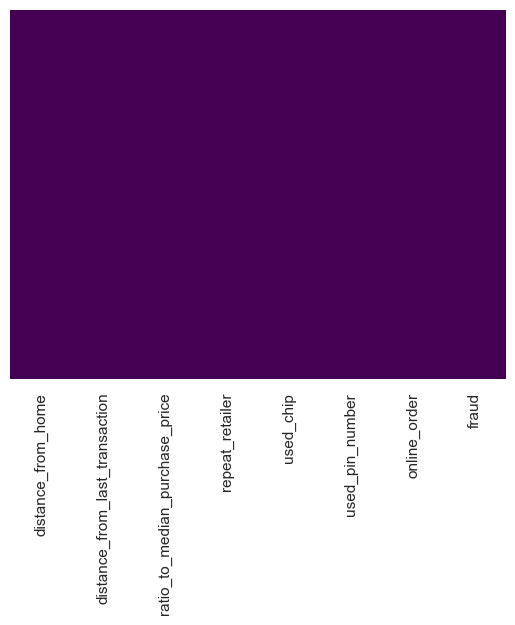

In [8]:
sns.heatmap(data.isnull(),yticklabels=False, cbar=False,cmap='viridis')

In [9]:
data.isnull().sum()

distance_from_home                0
distance_from_last_transaction    0
ratio_to_median_purchase_price    0
repeat_retailer                   0
used_chip                         0
used_pin_number                   0
online_order                      0
fraud                             0
dtype: int64

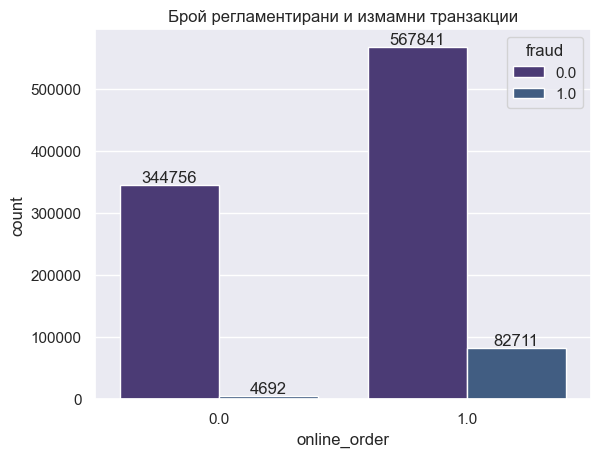

online_order  fraud
0.0           0.0      344756
              1.0        4692
1.0           0.0      567841
              1.0       82711
Name: fraud, dtype: int64

In [10]:
g = sns.countplot(x='online_order',hue='fraud', data=data)

for i in g.containers:
    g.bar_label(i)

plt.title("Number of legitimate and fraudulent transactions")
plt.show()

data.groupby(['online_order','fraud'])['fraud'].count()

# 3. Exploratory data analysis

**Fraud is 17.62 times more common in online purchases**

4,692 of 87,403 fraudulent transactions are not online

82,711 of 87,403 are online


**The dataset is imbalanced, because the number of legitimate transactions is much larger than the number of fraudulent ones.**

In [11]:
pv = data.pivot_table(index='online_order',columns='fraud',values='distance_from_home',aggfunc='count')
pv

fraud,0.0,1.0
online_order,,
0.0,344756,4692
1.0,567841,82711


In [12]:
pv['Fraud %']=pv[1]/(pv[0]+pv[1])
pv.style.format({'Fraud %':'{:.2%}'})

fraud,0.000000,1.000000,Fraud %
online_order,,,
0.000000,344756,4692,1.34%
1.000000,567841,82711,12.71%


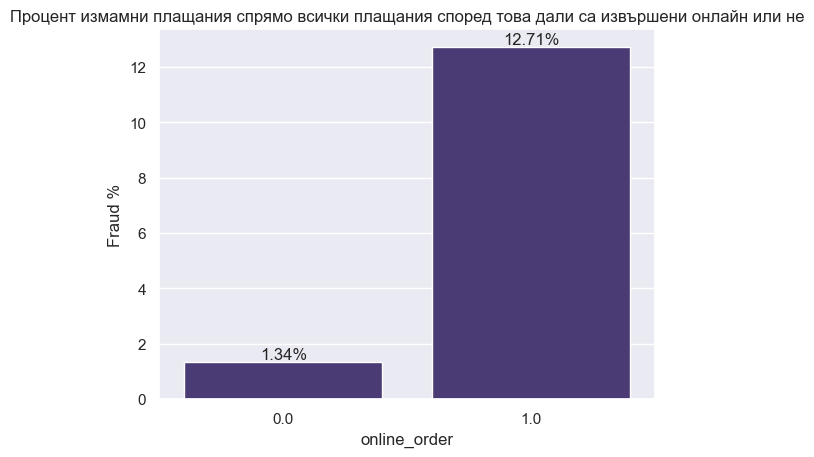

In [13]:
g=sns.barplot(x=pv.index, data=pv, y=pv['Fraud %']*100)
for i in g.containers:
    g.bar_label(i, fmt='%.2f%%')
g.set(title='Percentage of fraudulent payments out of all payments, online vs in person')
plt.show()

**The share of fraud in online payments is 12.71%, compared with 1.34% for in-person payments (9.5 times higher)**

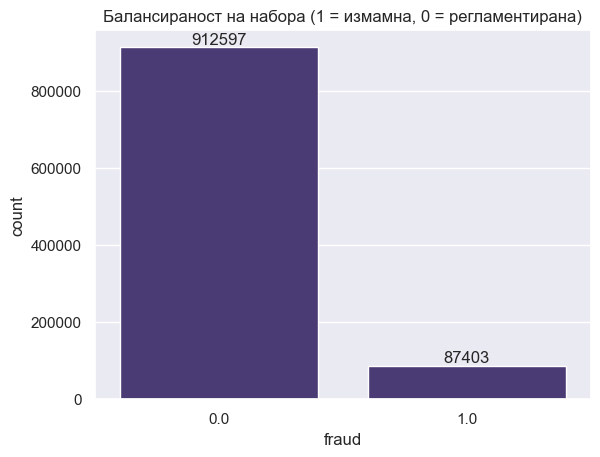

In [14]:
g = sns.countplot(x='fraud', data=data)
for i in g.containers:
    g.bar_label(i)
g.set(title='Class balance (1 = fraudulent, 0 = legitimate)')
plt.show()

**Imbalanced: 91.26% of the transactions are legitimate and 8.74% are fraudulent**

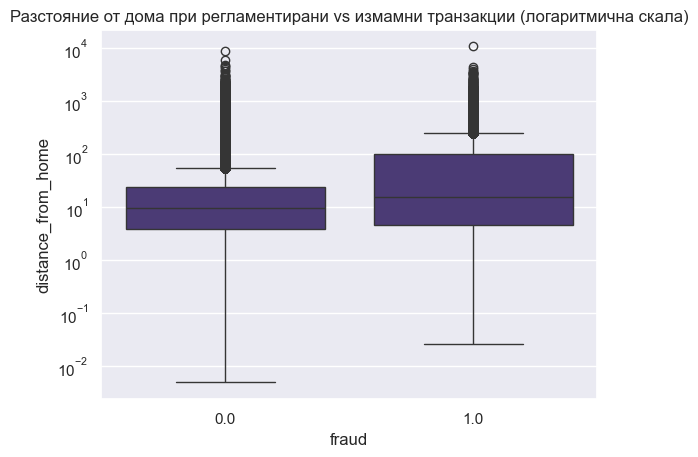

In [15]:
g = sns.boxplot(x='fraud', y='distance_from_home', data=data)
g.set(title='Distance from home, legitimate vs fraudulent transactions (log scale)')
plt.yscale('log')
plt.show()

**Logarithmic scale because of the wide spread of values (0 to 10,000 kilometres)**

In [16]:
medians = data.groupby('fraud')['distance_from_home'].median().reset_index()
medians

,fraud,distance_from_home
0,0.0,9.673847
1,1.0,15.454219


**The median distance for legitimate payments is 9.67 km, and for fraudulent ones it is 15.45 km. Fraudulent payments happen more often at a larger distance.**

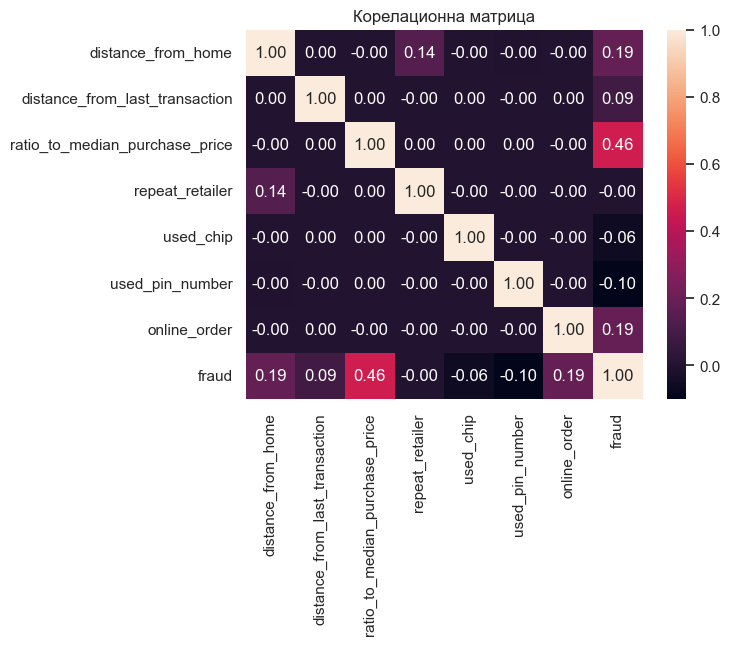

In [17]:
sns.heatmap(data.corr(), annot=True, fmt='.2f')
plt.title('Correlation matrix')
plt.show()

**The strongest positive correlation with fraud is the ratio to the median purchase price (0.46), followed by online payment (0.19) and distance from home (0.19)**

**Using a chip and/or a PIN code lowers the percentage of fraudulent payments**

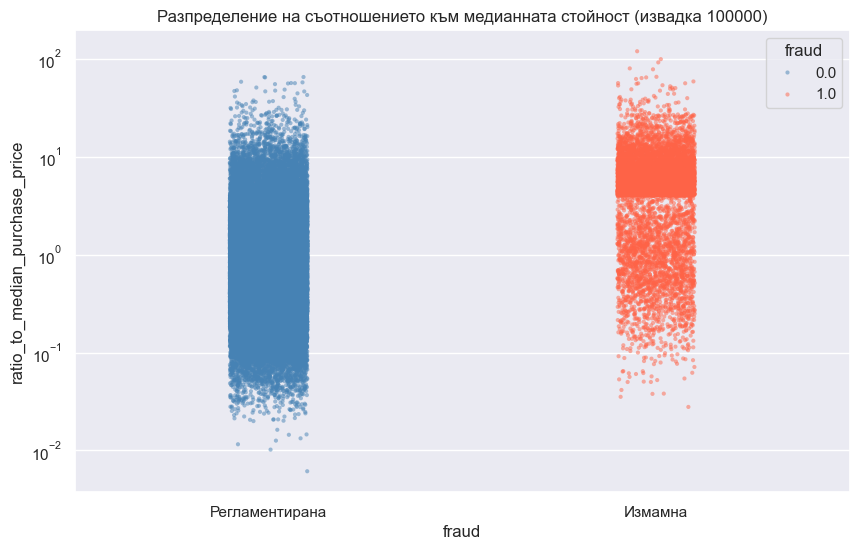

In [18]:
plt.figure(figsize=(10, 6))
sns.stripplot(x='fraud', y='ratio_to_median_purchase_price',
              data=data.sample(100000),
              hue='fraud', palette=['steelblue', 'tomato'],
              size=3, alpha=0.5)
plt.yscale('log')
plt.xticks([0, 1], ['Legitimate', 'Fraudulent'])
plt.title('Distribution of the ratio to the median purchase price (sample of 100,000)')
plt.show()

**Legitimate transactions are concentrated around 1 (ratio_to_median_purchase_price is the ratio between the value of the current transaction and the median value of all purchases of that cardholder.)**

**Fraudulent transactions are concentrated at values much higher than 1, which indicates an unusual transaction.**

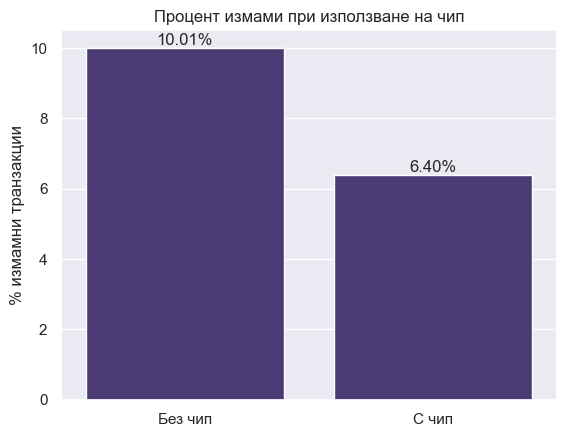

In [19]:
pv2 = data.pivot_table(index='used_chip', columns='fraud', values='distance_from_home', aggfunc='count')
pv2['Fraud %'] = pv2[1] / (pv2[0] + pv2[1])

g = sns.barplot(x=['No chip', 'Chip'], y=pv2['Fraud %']*100, data=pv2)
for i in g.containers:
    g.bar_label(i, fmt='%.2f%%')
g.set(title='Fraud percentage by chip use',
      xlabel='', ylabel='% fraudulent transactions')
plt.show()

**Paying with a chip is safer than paying without one (6.40% fraud rate with a chip versus 10.01% without)**

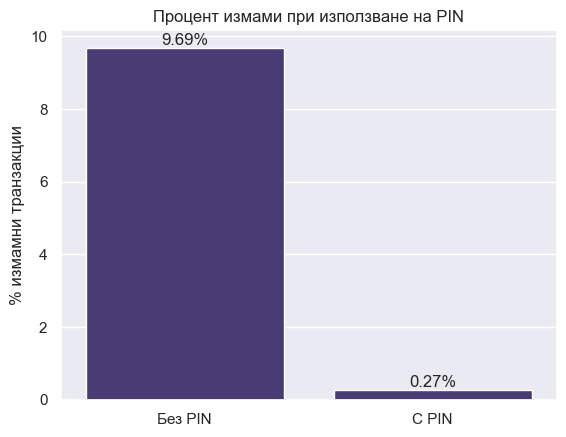

In [20]:
pv2 = data.pivot_table(index='used_pin_number', columns='fraud', values='distance_from_home', aggfunc='count')
pv2['Fraud %'] = pv2[1] / (pv2[0] + pv2[1])

g = sns.barplot(x=['No PIN', 'PIN'], y=pv2['Fraud %']*100, data=pv2)
for i in g.containers:
    g.bar_label(i, fmt='%.2f%%')
g.set(title='Fraud percentage by PIN use',
      xlabel='', ylabel='% fraudulent transactions')
plt.show()

**When a PIN code is used, the fraud rate drops to 0.27%, versus 9.69% without a PIN. Paying with a PIN is the safest method**

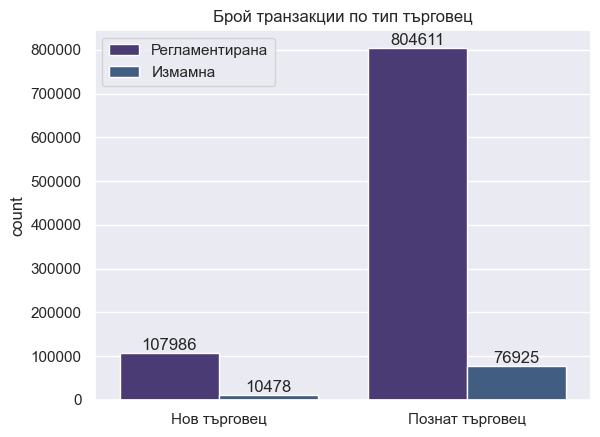

In [21]:
g = sns.countplot(x='repeat_retailer', hue='fraud', data=data)
for i in g.containers:
    g.bar_label(i)
g.set(title='Number of transactions by retailer type',
      xlabel='')
plt.xticks([0, 1], ['New retailer', 'Known retailer'])
plt.legend(labels=['Legitimate', 'Fraudulent'])
plt.show()

**There is no clear dependence on new versus known retailer: 9.6% fraud with a known retailer and 9.7% with a new one**

# 4. Data preparation

**All columns are already numeric**

In [22]:
from sklearn.model_selection import train_test_split

**We split the data into a training set and a test set in a 70:30 ratio**

In [23]:
np.random.seed(100)
X_train, X_test, y_train, y_test=train_test_split(
    data.drop('fraud', axis=1),data['fraud'], test_size=0.3,random_state=50,stratify=data['fraud'])

In [24]:
y_train = y_train.astype(int)
y_test = y_test.astype(int)

**In the dataset the variables are stored as float, so we convert the target to int**

# 5. Training the models

## Logistic regression

In [25]:
from sklearn.linear_model import LogisticRegression
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


---
**We train two models for each of the algorithms Decision Tree, Random Forest and XGBoost. The first model for each algorithm uses the default parameters, and for the second we find the optimal hyperparameter values with exhaustive (grid) or random search**

---

## Decision tree

**Default tree**

In [26]:
from sklearn.tree import DecisionTreeClassifier
dt1 = DecisionTreeClassifier(random_state=42)
dt1.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


**Tuned tree**

In [27]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
params = {'max_depth': [3, 5, 10],
          'min_samples_leaf': [3, 5, 10],
         'ccp_alpha':[0,0.005,0.01]}
dt2 = GridSearchCV(DecisionTreeClassifier(random_state=42), params, cv=3, scoring='balanced_accuracy', n_jobs=-1)
dt2.fit(X_train, y_train)

,estimator,DecisionTreeC...ndom_state=42)
,param_grid,"{'ccp_alpha': [0, 0.005, ...], 'max_depth': [3, 5, ...], 'min_samples_leaf': [3, 5, ...]}"
,scoring,'balanced_accuracy'
,n_jobs,-1
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [28]:
dt2.best_params_

{'ccp_alpha': 0, 'max_depth': 10, 'min_samples_leaf': 5}

## Random Forest

**Default forest**

In [29]:
rf1 = RandomForestClassifier(random_state=42)
rf1.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


**Tuned Forest**

In [30]:
params = {
    'max_depth': [5, 10],
    'min_samples_leaf': [5, 10],
    'n_estimators': [50, 100]
}

In [31]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

In [32]:
rf2 = RandomizedSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1), 
                          params, cv=3, scoring='balanced_accuracy', 
                          n_iter=5, n_jobs=-1, verbose=2, random_state=42)
rf2.fit(X_train, y_train)

Fitting 3 folds for each of 5 candidates, totalling 15 fits


,estimator,RandomForestC...ndom_state=42)
,param_distributions,"{'max_depth': [5, 10], 'min_samples_leaf': [5, 10], 'n_estimators': [50, 100]}"
,n_iter,5
,scoring,'balanced_accuracy'
,n_jobs,-1
,refit,True
,cv,3
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [33]:
rf2.best_params_

{'n_estimators': 100, 'min_samples_leaf': 5, 'max_depth': 10}

## XGBoost Classifier

**XGBoost Classifier**

In [34]:
from xgboost import XGBClassifier

In [35]:
xgb1 = XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss')

In [36]:
xgb1.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


**Tuned XGBoost Classifier**

In [37]:
params = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1, 0.3],
    'n_estimators': [100, 200],
    'min_child_weight': [1, 5]
}

In [38]:
xgb2 = RandomizedSearchCV(XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss'),
                           params, cv=3, scoring='balanced_accuracy', n_iter=5, n_jobs=-1, verbose=2)

In [39]:
import time

In [40]:
start=time.time()
xgb2.fit(X_train, y_train)
end=time.time()
print(end-start)

Fitting 3 folds for each of 5 candidates, totalling 15 fits
32.97036957740784


In [41]:
xgb2.best_params_

{'n_estimators': 200,
 'min_child_weight': 5,
 'max_depth': 5,
 'learning_rate': 0.1}

In [42]:
from sklearn.ensemble import StackingClassifier

In [43]:
estimators = [
    ('dt', dt2.best_estimator_),
    ('rf', rf2.best_estimator_),
    ('xgb', xgb2.best_estimator_)
]

stacking = StackingClassifier(estimators=estimators, 
                               final_estimator=LogisticRegression(),
                               n_jobs=-1)

In [44]:
stacking.fit(X_train, y_train)

,estimators,"[('dt', ...), ('rf', ...), ...]"
,final_estimator,LogisticRegression()
,cv,None
,stack_method,'auto'
,n_jobs,-1
,passthrough,False
,verbose,0
,criterion,'gini'
,splitter,'best'
,max_depth,10
,min_samples_split,2


**Stacking model trained on the predictions of the three best models**

## 6. Evaluating model performance

In [45]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score

**We define a function report_df that extracts the performance metrics of the models from the classification report.**

In [46]:
def report_df(model,model_id, positive=1, negative=0):
    """
    model - trained model
    model_id - user-friendly name of the model
    positive - positive class
    negative - negative class
    """
    
    clr=classification_report(y_test,model.predict(X_test),output_dict=True, digits=3)
    data={'model':str(model),
        'sensitivity':clr[str(positive)]['recall'],
         'specificity':clr[str(negative)]['recall'],
         'f1 score':clr[str(positive)]['f1-score'],
         'accuracy':clr['accuracy'],
         'balanced accuracy':clr['macro avg']['recall'],
          'AUC':roc_auc_score(y_test,model.predict_proba(X_test)[:,1])
         }
    return pd.DataFrame(data=data, index=[model_id])

**We define a list of the trained models with custom labels**

In [47]:
models = pd.DataFrame(data={
    'model': [log_model, dt1, dt2, rf1, rf2, xgb1, xgb2, stacking],
    'model id': ['LR', 'DT default', 'DT tuned', 'RF default', 'RF tuned', 'XGB default', 'XGB tuned', 'Stacking']
})

models

,model,model id
0,LogisticRegression(max_iter=1000),LR
1,DecisionTreeClassifier(random_state=42),DT default
2,"GridSearchCV(cv=3, estimator=DecisionTreeClass...",DT tuned
3,"(DecisionTreeClassifier(max_features='sqrt', r...",RF default
4,"RandomizedSearchCV(cv=3,\n e...",RF tuned
5,"XGBClassifier(base_score=None, booster=None, c...",XGB default
6,"RandomizedSearchCV(cv=3,\n e...",XGB tuned
7,"StackingClassifier(estimators=[('dt',\n ...",Stacking


**We create the dataframe report by applying the function to the models**

In [48]:
report = pd.DataFrame()
for item in models.index:
    model = models['model'][item]
    model_id = models['model id'][item]
    report = pd.concat([report, report_df(model, model_id, 1, 0)])
report

,model,sensitivity,specificity,f1 score,accuracy,balanced accuracy,AUC
LR,LogisticRegression(max_iter=1000),0.598261,0.993042,0.716089,0.958537,0.795651,0.968070
DT default,DecisionTreeClassifier(random_state=42),0.999886,0.999993,0.999905,0.999983,0.999939,0.999939
DT tuned,"GridSearchCV(cv=3, estimator=DecisionTreeClass...",0.999886,0.999989,0.999886,0.999980,0.999937,0.999939
RF default,RandomForestClassifier(random_state=42),0.999847,1.000000,0.999924,0.999987,0.999924,1.000000
RF tuned,"RandomizedSearchCV(cv=3,\n e...",0.999771,1.000000,0.999886,0.999980,0.999886,1.000000
XGB default,"XGBClassifier(base_score=None, booster=None, c...",0.990466,0.998933,0.989673,0.998193,0.994700,0.999971
XGB tuned,"RandomizedSearchCV(cv=3,\n e...",0.990428,0.999083,0.990428,0.998327,0.994755,0.999973
Stacking,"StackingClassifier(estimators=[('dt',\n ...",0.999809,0.999996,0.999886,0.999980,0.999903,1.000000


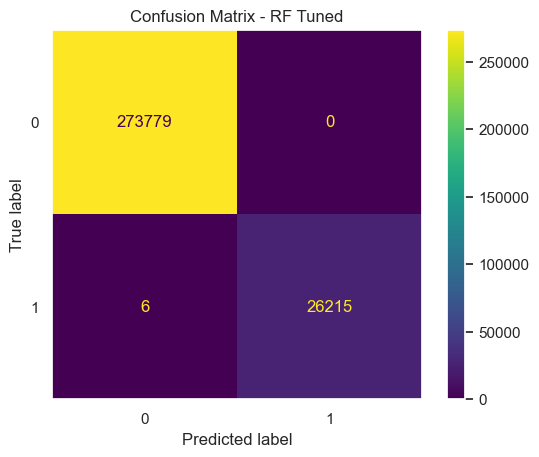

In [49]:
best_for_cm = rf2.best_estimator_
ConfusionMatrixDisplay.from_estimator(best_for_cm, X_test, y_test)
plt.title('Confusion Matrix - RF Tuned')
plt.grid(False)
plt.show()

**6 false negative fraudulent transactions**

**Comparing the models**

In [50]:
metrics=report.columns[1:]
metrics

Index(['sensitivity', 'specificity', 'f1 score', 'accuracy',
       'balanced accuracy', 'AUC'],
      dtype='object')

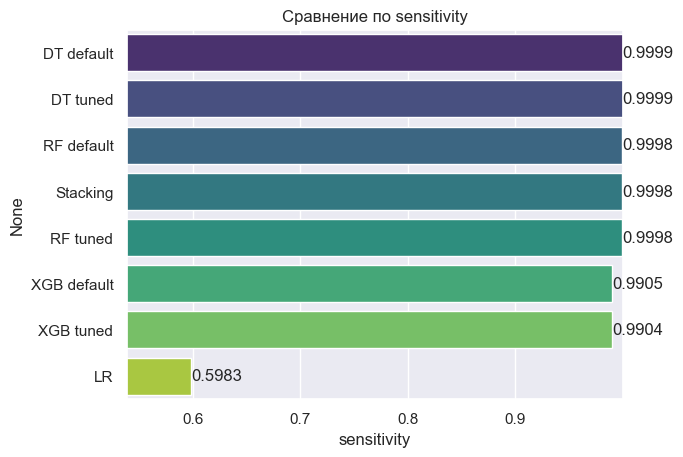

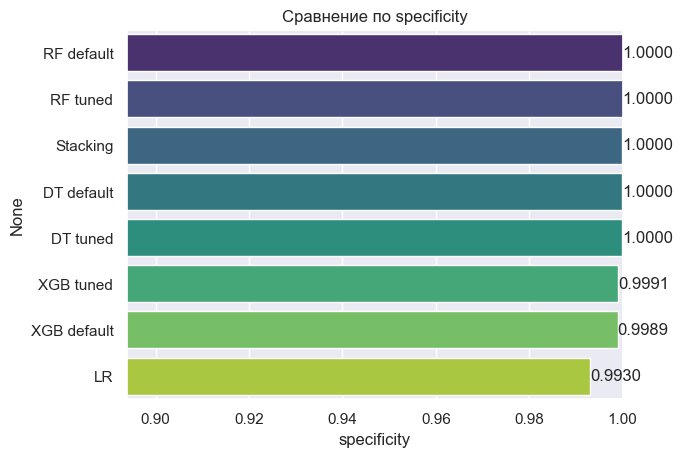

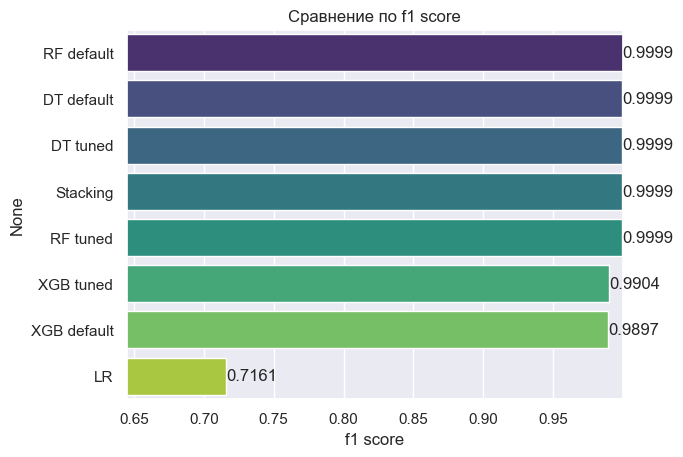

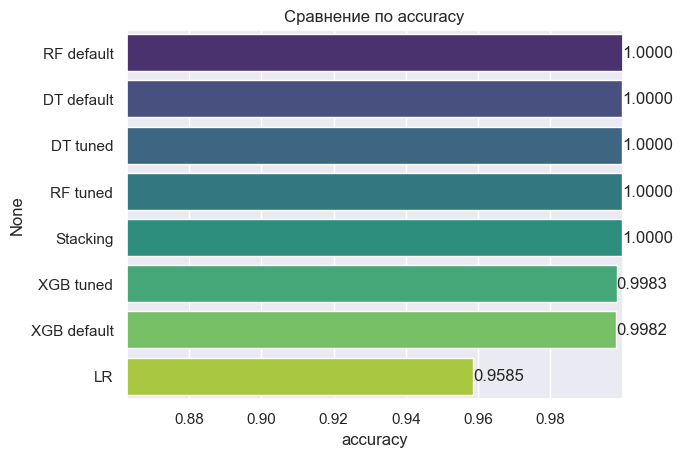

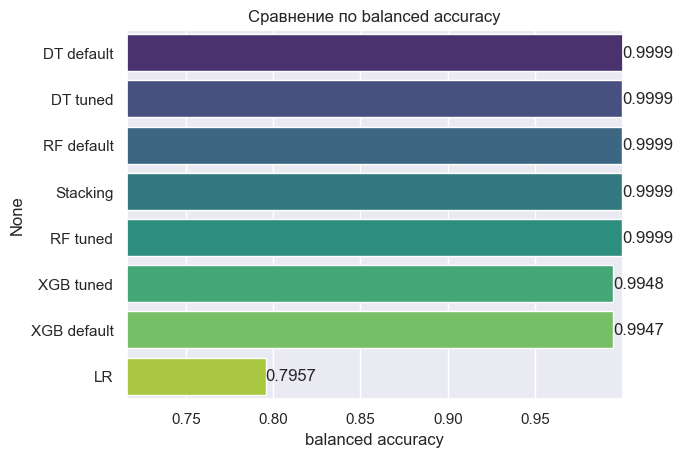

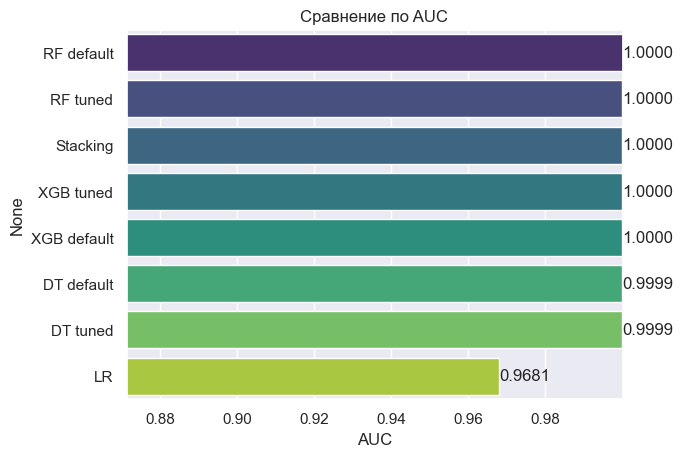

In [51]:
for metric in metrics:
    g = sns.barplot(data=report.sort_values(metric, ascending=False),
                    y=report.sort_values(metric, ascending=False).index,
                    x=metric,
                    hue=report.sort_values(metric, ascending=False).index,
                    palette='viridis',
                    legend=False)
    g.set(title="Comparison by " + metric)
    plt.xlim(left=report[metric].min()*0.9, right=report[metric].max())
    for i in g.containers:
        g.bar_label(i, fmt='%.4f')
    plt.show()

**Most models achieve extremely high results (AUC and balanced accuracy close to 1.00). This is due to the combination of a large amount of data (1 million transactions) and the fact that the dataset is synthetically generated.**

**No single model is better than the others on every metric. Logistic Regression is far behind the other models on sensitivity (0.5983) and balanced accuracy (0.7957)**

**Decision Tree and Random Forest (default and tuned) achieve the highest sensitivity (~0.9999). RF default and RF tuned achieve perfect specificity (1.0000) and AUC (1.0000).**

### From this comparison we can conclude that the best model is Random Forest default or RF tuned, because of the perfect AUC and specificity and the highest sensitivity. In sections 7 and 8 we interpret the predictions of this model.

# 7. Interpreting the models

## Variable Importance

**We choose the model with the optimized parameter values**

In [52]:
best = rf2.best_estimator_

**We calculate the relative importance of the features**

In [53]:
features=pd.DataFrame(data={'feature':list(X_test.columns),'importance':list(best.feature_importances_)})
features.sort_values('importance', ascending=False, inplace=True)
features

,feature,importance
2,ratio_to_median_purchase_price,0.525494
6,online_order,0.166085
0,distance_from_home,0.139962
5,used_pin_number,0.061615
4,used_chip,0.054436
1,distance_from_last_transaction,0.045737
3,repeat_retailer,0.006671


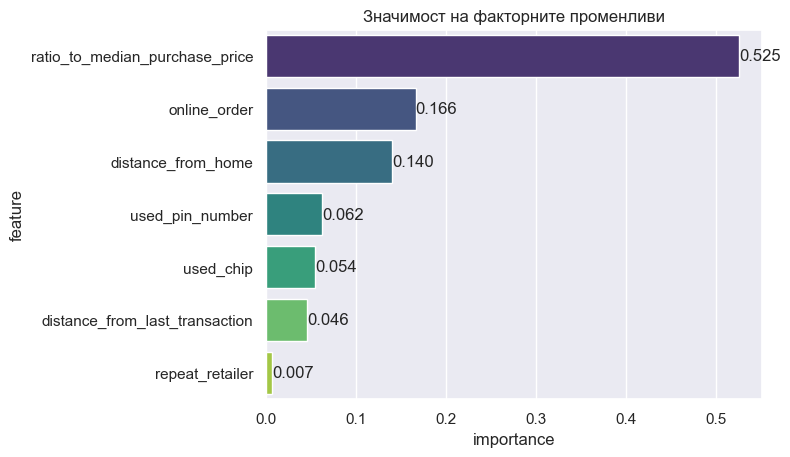

In [54]:
g=sns.barplot(x='importance',y='feature',data=features,hue ='feature', palette='viridis')
for i in g.containers:
    g.bar_label(i,fmt='%.3f')
g.set_title('Feature importance')
plt.show()

## The most important feature is ratio_to_median_purchase_price, second is whether the transaction is in person or online (online_order), and third is the distance from home (distance_from_home). In fourth, fifth and sixth place are used_pin_number, used_chip and distance_from_last_transaction, which also influence the result. Last is whether the retailer has been used before, which hardly matters.

## SHAP summary plot

**Global-level explanation**

In [55]:
import shap
shap.initjs()
import warnings
warnings.filterwarnings('ignore')

In [56]:
explainer=shap.TreeExplainer(model=best)

In [57]:
X_test_sample = X_test.sample(10000, random_state=42)

**A sample is used for faster computation**

In [58]:
shap_obj=explainer(X_test_sample)

In [59]:
shap_obj.values[:2]

array([[[ 0.00378211, -0.00378211],
        [ 0.00386188, -0.00386188],
        [ 0.06744368, -0.06744368],
        [-0.00960328,  0.00960328],
        [-0.00762573,  0.00762573],
        [-0.00415596,  0.00415596],
        [ 0.03158884, -0.03158884]],

       [[ 0.01196839, -0.01196839],
        [ 0.00373805, -0.00373805],
        [ 0.07741878, -0.07741878],
        [ 0.00128091, -0.00128091],
        [ 0.01449514, -0.01449514],
        [-0.0047679 ,  0.0047679 ],
        [-0.01884502,  0.01884502]]])

In [60]:
shap_obj.values.shape

(10000, 7, 2)

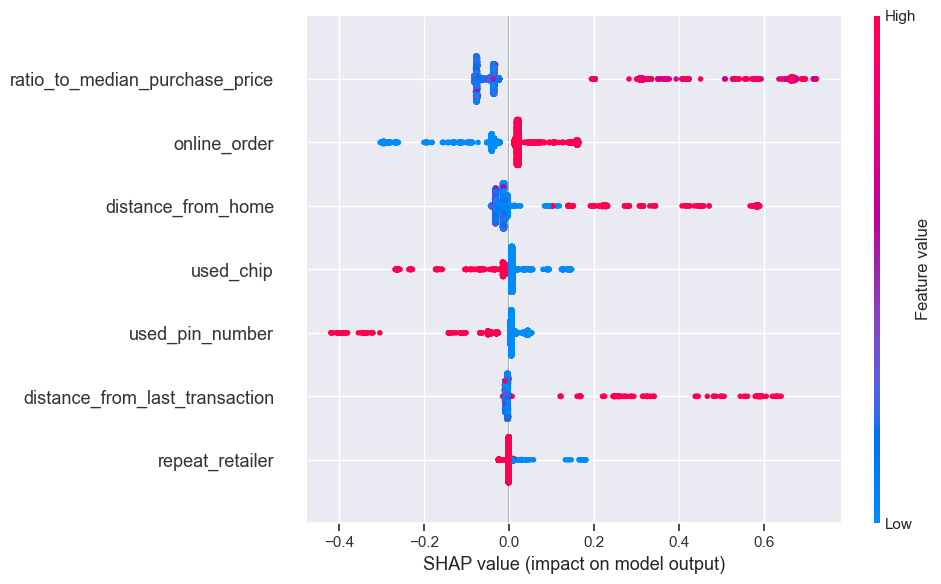

In [61]:
shap.summary_plot(shap_values=np.take(shap_obj.values,1,axis=-1),
                  features=X_test_sample,
                  feature_names=list(X_test.columns),
                 plot_size=(10,6))

 - **ratio_to_median_purchase_price contributes the most to fraudulent transactions: higher values (red) push towards fraud = 1 (fraudulent transaction), and lower values (blue) push towards fraud = 0 (legitimate transaction)**
 - **online_order is second: higher values (red) push towards fraud = 1 (fraudulent transaction), and lower values (blue) push towards fraud = 0 (legitimate transaction)**
 - **distance_from_home is third: higher values (red) push towards fraud = 1 (fraudulent transaction), and lower values (blue) contribute slightly to fraud = 0 (legitimate transaction)**

- **In fourth and fifth place are used_chip and used_pin_number. Unlike the first three, low values (blue) push towards fraud = 1, and high values (red) push towards fraud = 0**

- **In sixth place is distance_from_last_transaction: higher values (red) push towards fraud = 1 (fraudulent transaction), and lower values (blue) have no significant contribution**

- **In last place is repeat_retailer: higher values (red) have no contribution to fraud, and lower values (blue) have a slight contribution to fraud = 1**

# 8. Explaining individual predictions

## Legitimate

In [62]:
reglamentirani = X_test_sample[(y_test[X_test_sample.index] == 0) & 
                                (best.predict(X_test_sample) == 0)].index
reg = X_test_sample.index.get_loc(reglamentirani[0])

X_test_sample.iloc[[reg]]

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order
468098,0.593452,0.149419,0.912411,0.0,0.0,0.0,0.0


**reglamentirani = X_test_sample[(y_test[X_test_sample.index] == 0) &
                                (best.predict(X_test_sample) == 0)].index - finding a correctly predicted legitimate transaction in the sample**

In [63]:
y_test[reglamentirani[0]] #Fraud = 0

np.int64(0)

In [64]:
best.predict_proba(X_test_sample.iloc[[reg]])

array([[0.99791649, 0.00208351]])

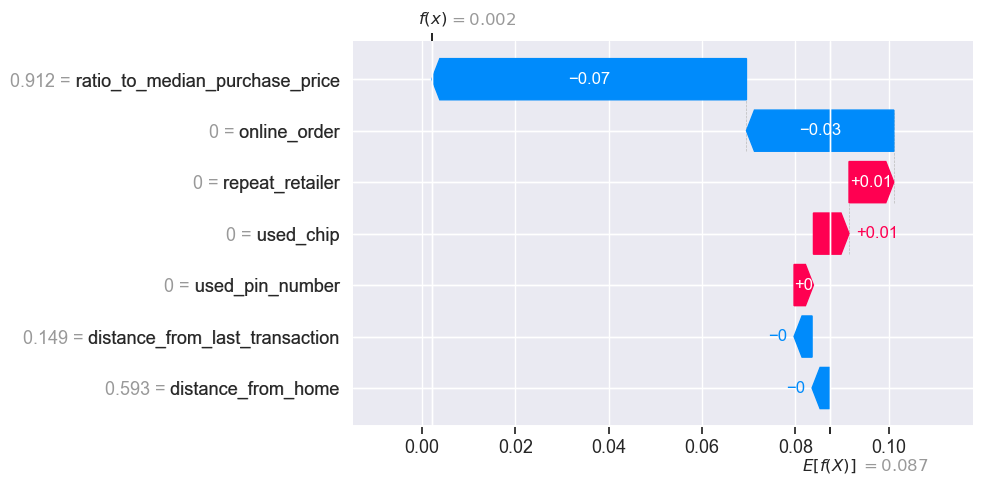

In [65]:
shap.waterfall_plot(shap_obj[reg][:, 1])

**The model predicted Fraud=0, which is a correct negative prediction (probability ~0.998). The features that contribute most to this prediction are ratio_to_median_purchase_price = 0.912 and online_order = 0.**

**The SHAP values of the features can also be shown with the following force plot**

In [72]:
shap.initjs()
shap.force_plot(explainer.expected_value[1], shap_obj.values[reg][:,1], X_test_sample.iloc[reg,:])

## Fraudulent

In [67]:
izmamni = X_test_sample[(y_test[X_test_sample.index] == 1) & 
                        (best.predict(X_test_sample) == 1)].index
fraud = X_test_sample.index.get_loc(izmamni[0])

X_test_sample.iloc[[fraud]]

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order
249577,57.929212,6.295209,6.003275,1.0,0.0,0.0,1.0


**izmamni = X_test_sample[(y_test[X_test_sample.index] == 1) &
                        (best.predict(X_test_sample) == 1)].index - finding a correctly predicted fraudulent transaction in the sample**

In [68]:
y_test[izmamni[0]]

np.int64(1)

In [69]:
best.predict_proba(X_test_sample.iloc[[fraud]])

array([[0.06412069, 0.93587931]])

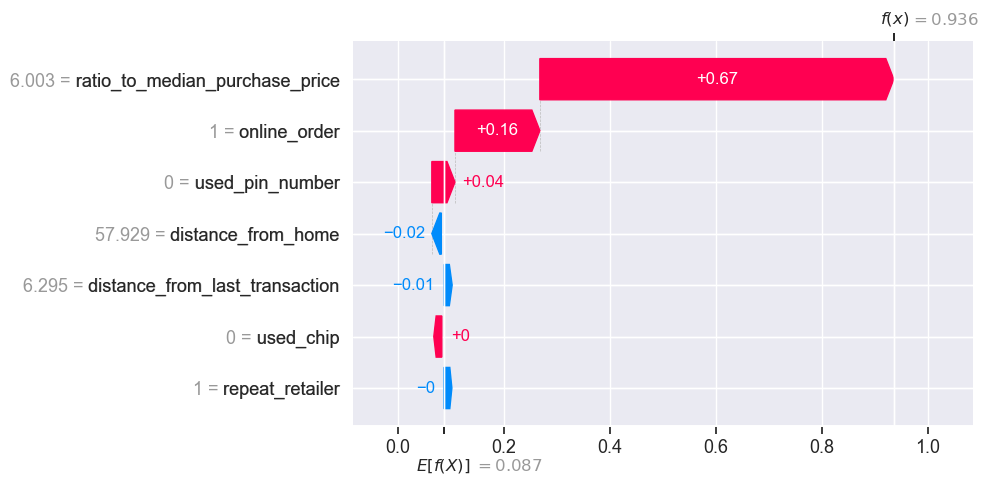

In [73]:
shap.initjs()
shap.waterfall_plot(shap_obj[fraud][:, 1])

**The model predicted Fraud=1, which is a correct positive prediction (probability ~0.94). The features that contribute most to this prediction are ratio_to_median_purchase_price = 6.003, online_order = 1 and used_pin_number = 0.**

**The SHAP values of the features can also be shown with the following force plot**

In [71]:
shap.force_plot(explainer.expected_value[1], shap_obj.values[fraud][:,1], X_test_sample.iloc[fraud,:])